In [72]:
import matplotlib.pyplot as plt
import os
import numpy as np
from monai.transforms import LoadImage, EnsureChannelFirst, Orientation, Compose
from monai.bundle import ConfigParser, download
import torch


In [73]:
# dicom_file_path = 'data/normal_cases/AG 519880_37F/DICOM/EXP00000/'
# dicom_file_path = 'data/normal_cases/ASJ 05633540_68F/DICOM/EXP00000/'
dicom_file_path = 'data/takotsubo_cases/testing_subset/JNMP 02291631/DICOM/EXP00000/'

image_loader = LoadImage(image_only=True)
CT = image_loader(dicom_file_path)

CT.meta

{'00200037': {'vr': 'DS', 'Value': [1.0, 0.0, 0.0, 0.0, 1.0, 0.0]},
 '00200032': {'vr': 'DS', 'Value': [-199.6093, -199.6093, 1796.5]},
 '00280030': {'vr': 'DS', 'Value': [0.781, 0.781, 2.0]},
 'spacing': array([0.781, 0.781, 2.   ]),
 'lastImagePositionPatient': array([-199.6093, -199.6093, 1496.5   ]),
 spatial_shape: (512, 512, 151),
 space: RAS,
 original_affine: array([[-7.810000e-01,  0.000000e+00,  0.000000e+00,  1.996093e+02],
        [ 0.000000e+00, -7.810000e-01,  0.000000e+00,  1.996093e+02],
        [ 0.000000e+00,  0.000000e+00, -2.000000e+00,  1.796500e+03],
        [ 0.000000e+00,  0.000000e+00,  0.000000e+00,  1.000000e+00]]),
 affine: tensor([[-7.8100e-01,  0.0000e+00,  0.0000e+00,  1.9961e+02],
         [ 0.0000e+00, -7.8100e-01,  0.0000e+00,  1.9961e+02],
         [ 0.0000e+00,  0.0000e+00, -2.0000e+00,  1.7965e+03],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]],
        dtype=torch.float64),
 original_channel_dim: nan,
 'filename_or_obj': 'data/tako

In [74]:
CT.shape

torch.Size([512, 512, 151])

In [75]:
CT_coronal_slice = CT[:,256].cpu().numpy()

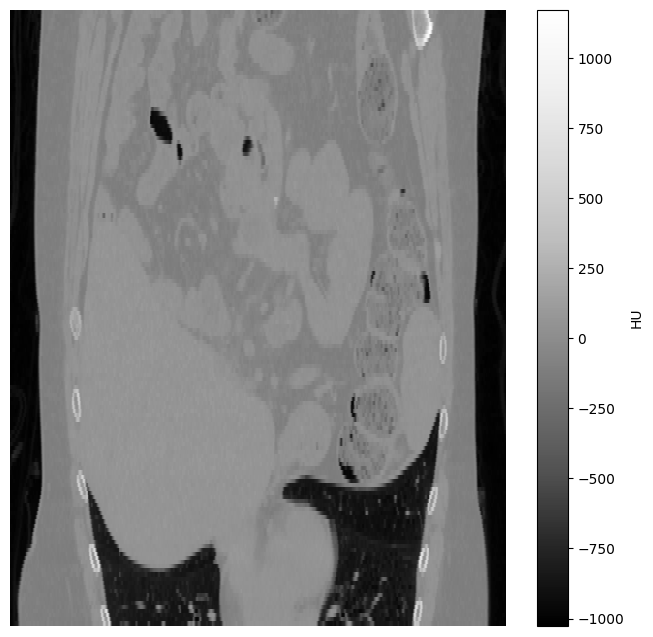

In [76]:
plt.figure(figsize=(8,8))
plt.pcolormesh(CT_coronal_slice.T, cmap='Greys_r')
plt.colorbar(label='HU')
plt.axis('off')
plt.show()

In [151]:
preprocessing_pipeline = Compose([
    LoadImage(image_only=True),
    EnsureChannelFirst(),
    Orientation(axcodes='LPS')
])

In [152]:
CT = preprocessing_pipeline(dicom_file_path)
print(CT.shape)

torch.Size([1, 512, 512, 151])


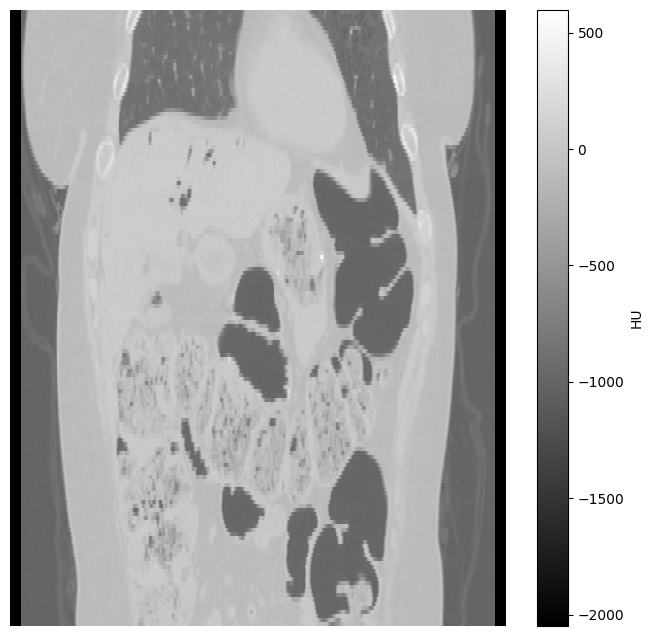

In [155]:
CT_coronal_slice = CT[0, :, 180, :].cpu().numpy()

plt.figure(figsize=(8,8))
plt.pcolormesh(CT_coronal_slice.T, cmap='gray')
plt.colorbar(label='HU')
plt.axis('off')
plt.show()

In [80]:
model_name = "wholeBody_ct_segmentation"
data_directory = 'data/'
# download(name=model_name, bundle_dir=data_directory)

In [81]:
model_path = os.path.join(data_directory, 'wholeBody_ct_segmentation', 'models', 'model_lowres.pt')
config_path = os.path.join(data_directory, 'wholeBody_ct_segmentation', 'configs', 'inference.json')

In [82]:
config = ConfigParser()
config.read_config(config_path)

In [83]:
preprocessor = config.get_parsed_content("preprocessing")

model = config.get_parsed_content("network")
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model.eval()

inferer = config.get_parsed_content("inferer")

postprocessor = config.get_parsed_content("postprocessing")

/var/folders/jm/k37qm_7n7dj5fp2rnwhd32y80000gn/T/ipykernel_3289/455294333.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_path, ma

In [84]:
output = preprocessor({'image': dicom_file_path}) 

with torch.no_grad():
    # Have to add additional batch dimension to feed into model
    output['pred'] = inferer(output['image'].unsqueeze(0), network=model)
    
# Remove batch dimension in image and prediction
output['pred'] = output['pred'][0]
output['image'] = output['image'][0]

print("Unique values before postprocessing:", torch.unique(output['pred']))

# Apply postprocessing to data
output = postprocessor(output)

print("Unique values after postprocessing:", torch.unique(output['pred']))


segmentation = torch.flip(output['pred'][0], dims=[2])
segmentation = segmentation.cpu().numpy()


Unique values before postprocessing: metatensor([-26.4484, -25.8113, -25.6537,  ...,  17.1888,  17.1953,  17.2351])
2024-11-05 22:35:17,417 INFO image_writer.py:197 - writing: eval/EXP00000/EXP00000_trans.nii.gz
Unique values after postprocessing: metatensor([ 0.,  5.,  6., 13., 14., 50., 82., 84., 91., 95.])


In [85]:
segmentation.shape

(512, 512, 151)

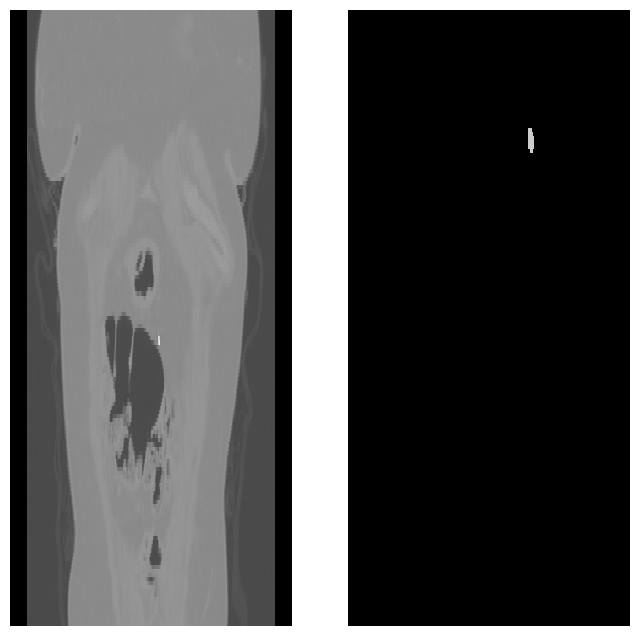

In [104]:
slice_num = 135
CT_coronal_slice = CT[0,:, slice_num].cpu().numpy()
segmentation_coronal_slice = segmentation[:, slice_num]

plt.subplots(1,2,figsize=(8,8))
plt.subplot(121)
plt.pcolormesh(CT_coronal_slice.T, cmap='grey')
plt.axis('off')
plt.subplot(122)
plt.pcolormesh(segmentation_coronal_slice.T, cmap='nipy_spectral')
plt.axis('off')
plt.show()


In [ ]:
import nibabel as nib
from totalsegmentator.python_api import totalsegmentator


# option 1: provide input and output as file paths
output_directory = "data/segment_eval_output_takotsubo"
output_image = totalsegmentator(dicom_file_path, output_directory, license_number="aca_BWYHC6UQQFDU8A", task="heartchambers_highres")

# option 2: provide input and output as nifti image objects
# input_img = nib.load(dicom_file_path)
# output_img = totalsegmentator(input_img)
# print(output_img)
# nib.save(output_img, data_directory)

No GPU detected. Running on CPU. This can be very slow. The '--fast' or the `--roi_subset` option can help to reduce runtime.

If you use this tool please cite: https://pubs.rsna.org/doi/10.1148/ryai.230024

Generating rough segmentation for cropping...
Converting dicom to nifti...
  found image with shape (512, 512, 151)
Resampling...
  Resampled in 1.26s
Predicting...


/Users/awabakram/git/Takotsubo-Syndrome/myenv/lib/python3.9/site-packages/nnunetv2/inference/predict_from_raw_data.py:84: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  check

  Predicted in 11.75s
Resampling...
Converting dicom to nifti...
  found image with shape (512, 512, 151)
  cropping from (512, 512, 151) to (197, 182, 46)
Predicting...


Python(11184) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11185) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11186) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11187) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11188) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11189) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11190) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11191) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11192) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11193) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11194) Malloc

  Predicted in 473.19s
Saving segmentations...


Python(11472) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11473) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11474) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11475) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11476) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(11477) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


  0%|          | 0/7 [00:00<?, ?it/s]

Creating heart_myocardium.nii.gzCreating heart_atrium_left.nii.gz

Creating heart_atrium_right.nii.gzCreating heart_ventricle_left.nii.gz
Creating heart_ventricle_right.nii.gz

Creating aorta.nii.gz
Creating pulmonary_artery.nii.gz
  Saved in 1.52s



<class 'nibabel.nifti1.Nifti1Image'>
data shape (512, 512, 151)
affine:
[[-7.81000018e-01  0.00000000e+00  0.00000000e+00  1.99609299e+02]
 [-0.00000000e+00  7.81000018e-01  0.00000000e+00 -1.99481705e+02]
 [ 0.00000000e+00 -0.00000000e+00  2.00000000e+00  1.49650000e+03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
metadata:
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b''
dim_info        : 0
dim             : [  3 512 512 151   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : uint8
bitpix          : 8
slice_start     : 0
pixdim          : [-1.     0.781  0.781  2.     1.     1.     1.     1.   ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 2
cal_max         : 0.0
cal_min 

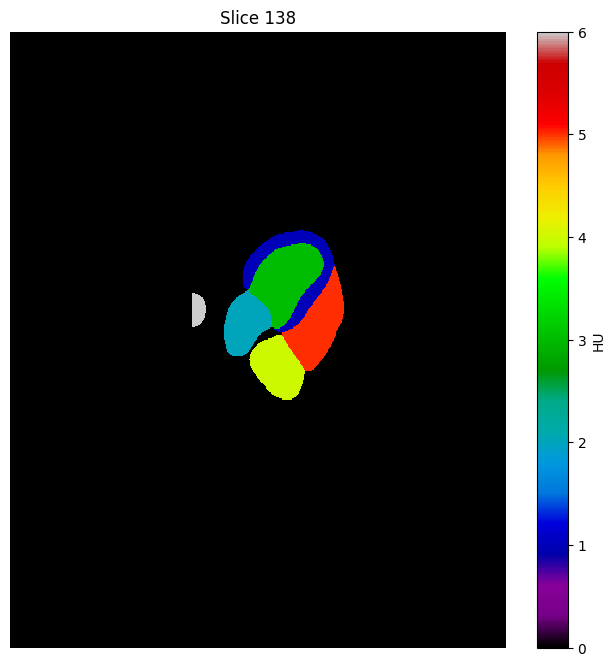

In [195]:
nib.save(output_image, 'output_image.nii.gz')
%matplotlib inline
slice_num = 138

print(output_image)

plt.figure(figsize=(8,8))
plt.pcolormesh(output_image.get_fdata()[:, : , slice_num], cmap='nipy_spectral')
plt.colorbar(label='HU')
plt.title(f"Slice {slice_num}")
plt.axis('off')
plt.show()

<class 'monai.data.meta_tensor.MetaTensor'>
torch.Size([512, 512, 515])


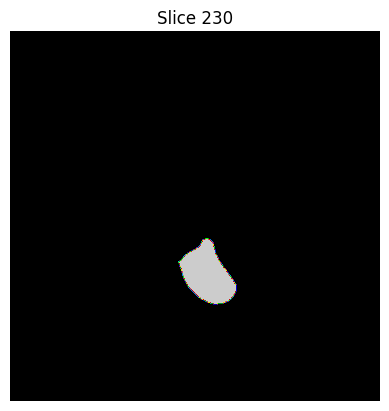

In [ ]:


# Create a LoadImage transform instance
# load_image = LoadImage(image_only=True)

# Load the image
image = image_loader(f"data/segment_eval_output/heart_ventricle_left.nii.gz")


# Check the image type and shape
print(type(image))  # Should be a PyTorch Tensor or NumPy array
print(image.shape)  # Shows the dimensions of the loaded image

slice_num = 230

# Display a slice of the image
plt.imshow(image[:, :, slice_num], cmap='nipy_spectral')
plt.title(f"Slice {slice_num}")
plt.axis('off')
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import SGD
import seaborn as sns


